# TMDB Movie Recommendation System
### Content-based filtering | Data Analyst Notebook

**Goal:** Build a movie recommendation system from the two TMDB datasets (`tmdb_5000_movies.csv` and `tmdb_5000_credits.csv`).

This notebook follows a practical analytics workflow:
1. Load and inspect both datasets.
2. Clean and merge the data using movie titles.
3. Explore useful movie attributes.
4. Engineer a combined metadata “soup” from genres, keywords, cast, director, and overview.
5. Convert the text into TF-IDF vectors and recommend similar movies using cosine similarity.
6. Test recommendations and discuss limitations.

**Recommendation approach:** Content-based filtering. It recommends films with similar descriptive metadata; it does not learn from individual user ratings or watch history.

In [1]:
# 1. Import libraries
import ast
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 2. Load the datasets

Place both CSV files in the same folder as this notebook, or update the paths below. The code also checks `/mnt/data`, which is commonly used in hosted notebook environments.

In [2]:
def find_csv(filename):
    candidates = [
        filename,
        os.path.join(".", filename),
        os.path.join("/mnt/data", filename),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        f"Could not find {filename}. Put it beside this notebook or update the path."
    )

movies_path = find_csv("tmdb_5000_movies.csv")
credits_path = find_csv("tmdb_5000_credits.csv")

movies = pd.read_csv(movies_path)
credits = pd.read_csv(credits_path)

print("Movies dataset shape:", movies.shape)
print("Credits dataset shape:", credits.shape)
display(movies.head(3))
display(credits.head(3))

Movies dataset shape: (4803, 20)
Credits dataset shape: (4803, 4)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {""id"": 878, ""name"": ""...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"": 2964, ""name"": ""future""}, {""id"": 3386, ""name"": ""space war""}, {""id"": 33...",en,Avatar,"In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn bet...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289}, {""name"": ""Twentieth Century Fox Film Corporation"", ""id"": 306}, {""na...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}, {""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""}]",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {""id"": 28, ""name"": ""Action""}]",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""name"": ""drug abuse""}, {""id"": 911, ""name"": ""exotic island""}, {""id"": 1319,...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, has come back to life and is headed to the edge of the Earth with Will T...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""name"": ""Jerry Bruckheimer Films"", ""id"": 130}, {""name"": ""Second Mate Pr...","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}]",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 80, ""name"": ""Crime""}]",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name"": ""based on novel""}, {""id"": 4289, ""name"": ""secret agent""}, {""id"": 966...",en,Spectre,A cryptic message from Bond’s past sends him on a trail to uncover a sinister organization. While M battles politica...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""name"": ""Danjaq"", ""id"": 10761}, {""name"": ""B24"", ""id"": 69434}]","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""}, {""iso_3166_1"": ""US"", ""name"": ""United States of America""}]",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""}, {""iso_639_1"": ""en"", ""name"": ""English""}, {""iso_639_1"": ""es"", ""name"": ""...",Released,A Plan No One Escapes,Spectre,6.3,4466


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""credit_id"": ""5602a8a7c3a3685532001c9a"", ""gender"": 2, ""id"": 65731, ""nam...","[{""credit_id"": ""52fe48009251416c750aca23"", ""department"": ""Editing"", ""gender"": 0, ""id"": 1721, ""job"": ""Editor"", ""name""..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Sparrow"", ""credit_id"": ""52fe4232c3a36847f800b50d"", ""gender"": 2, ""id"": 85,...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""department"": ""Camera"", ""gender"": 2, ""id"": 120, ""job"": ""Director of Photo..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""credit_id"": ""52fe4d22c3a368484e1d8d6b"", ""gender"": 2, ""id"": 8784, ""name"":...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""department"": ""Sound"", ""gender"": 2, ""id"": 153, ""job"": ""Original Music Com..."


## 3. Initial data quality checks

Check column names, data types, missing values, and duplicate records before merging.

In [3]:
print("Movies columns:")
print(movies.columns.tolist())
print("\\nCredits columns:")
print(credits.columns.tolist())

quality_summary = pd.DataFrame({
    "movies_missing": movies.isna().sum(),
    "movies_missing_pct": (movies.isna().mean() * 100).round(2),
})
display(quality_summary.sort_values("movies_missing", ascending=False).head(15))

print("Duplicate rows in movies:", movies.duplicated().sum())
print("Duplicate rows in credits:", credits.duplicated().sum())

Movies columns:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']
\nCredits columns:
['movie_id', 'title', 'cast', 'crew']


,movies_missing,movies_missing_pct
homepage,3091,64.36
tagline,844,17.57
overview,3,0.06
runtime,2,0.04
release_date,1,0.02
id,0,0.00
budget,0,0.00
genres,0,0.00
original_title,0,0.00
popularity,0,0.00


Duplicate rows in movies: 0
Duplicate rows in credits: 0


## 4. Merge and select relevant fields

The datasets both contain a movie title, and the movies dataset has a numeric `id` while the credits dataset has a `movie_id`. We use a **left merge** so movies remain in the main dataset, and check the resulting row count.

In [4]:
# Rename credits.movie_id to id if needed, then merge
credits_for_merge = credits.copy()
if "movie_id" in credits_for_merge.columns:
    credits_for_merge = credits_for_merge.rename(columns={"movie_id": "id"})

df = movies.merge(
    credits_for_merge[["id", "title", "cast", "crew"]],
    on="id",
    how="left",
    suffixes=("", "_credits")
)

# Keep one clear title field
if "title_credits" in df.columns:
    df["title"] = df["title"].fillna(df["title_credits"])
    df = df.drop(columns=["title_credits"])

print("Merged dataset shape:", df.shape)
print("Unique movie IDs:", df["id"].nunique())
display(df[["id", "title", "genres", "keywords", "cast", "crew"]].head(3))

Merged dataset shape: (4803, 22)
Unique movie IDs: 4803


,id,title,genres,keywords,cast,crew
0,19995,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {""id"": 878, ""name"": ""...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"": 2964, ""name"": ""future""}, {""id"": 3386, ""name"": ""space war""}, {""id"": 33...","[{""cast_id"": 242, ""character"": ""Jake Sully"", ""credit_id"": ""5602a8a7c3a3685532001c9a"", ""gender"": 2, ""id"": 65731, ""nam...","[{""credit_id"": ""52fe48009251416c750aca23"", ""department"": ""Editing"", ""gender"": 0, ""id"": 1721, ""job"": ""Editor"", ""name""..."
1,285,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""name"": ""Fantasy""}, {""id"": 28, ""name"": ""Action""}]","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""name"": ""drug abuse""}, {""id"": 911, ""name"": ""exotic island""}, {""id"": 1319,...","[{""cast_id"": 4, ""character"": ""Captain Jack Sparrow"", ""credit_id"": ""52fe4232c3a36847f800b50d"", ""gender"": 2, ""id"": 85,...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""department"": ""Camera"", ""gender"": 2, ""id"": 120, ""job"": ""Director of Photo..."
2,206647,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""name"": ""Adventure""}, {""id"": 80, ""name"": ""Crime""}]","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name"": ""based on novel""}, {""id"": 4289, ""name"": ""secret agent""}, {""id"": 966...","[{""cast_id"": 1, ""character"": ""James Bond"", ""credit_id"": ""52fe4d22c3a368484e1d8d6b"", ""gender"": 2, ""id"": 8784, ""name"":...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""department"": ""Sound"", ""gender"": 2, ""id"": 153, ""job"": ""Original Music Com..."


## 5. Exploratory data analysis (EDA)

First, inspect popularity, vote counts, release dates, and the most common genres. These checks help describe the dataset; they are not used as a substitute for similarity matching.

In [5]:
# Convert numeric fields safely
for col in ["popularity", "vote_average", "vote_count", "budget", "revenue", "runtime"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "release_date" in df.columns:
    df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

print("Number of movies:", len(df))
print("Unique titles:", df["title"].nunique())
print("Release date range:",
      df["release_date"].min() if "release_date" in df else "N/A",
      "to",
      df["release_date"].max() if "release_date" in df else "N/A")
display(df[["popularity", "vote_average", "vote_count", "runtime"]].describe().T)

Number of movies: 4803
Unique titles: 4800
Release date range: 1916-09-04 00:00:00 to 2017-02-03 00:00:00


,count,mean,std,min,25%,50%,75%,max
popularity,4803.0,21.492301,31.816650,0.0,4.66807,12.921594,28.313505,875.581305
vote_average,4803.0,6.092172,1.194612,0.0,5.60000,6.200000,6.800000,10.000000
vote_count,4803.0,690.217989,1234.585891,0.0,54.00000,235.000000,737.000000,13752.000000
runtime,4801.0,106.875859,22.611935,0.0,94.00000,103.000000,118.000000,338.000000


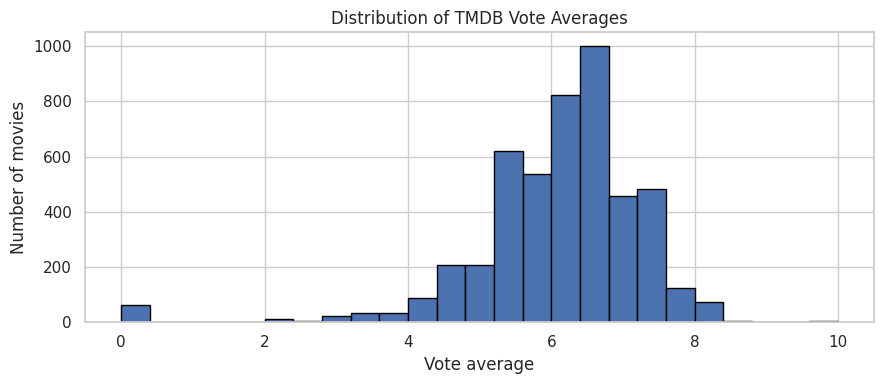

,title,popularity,vote_average,vote_count
0,Minions,875.581305,6.4,4571
1,Interstellar,724.247784,8.1,10867
2,Deadpool,514.569956,7.4,10995
3,Guardians of the Galaxy,481.098624,7.9,9742
4,Mad Max: Fury Road,434.278564,7.2,9427
5,Jurassic World,418.708552,6.5,8662
6,Pirates of the Caribbean: The Curse of the Black Pearl,271.972889,7.5,6985
7,Dawn of the Planet of the Apes,243.791743,7.3,4410
8,The Hunger Games: Mockingjay - Part 1,206.227151,6.6,5584
9,Big Hero 6,203.734590,7.8,6135


In [6]:
# Distribution of vote averages
plt.figure(figsize=(9, 4))
plt.hist(df["vote_average"].dropna(), bins=25, edgecolor="black")
plt.title("Distribution of TMDB Vote Averages")
plt.xlabel("Vote average")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()

# Top 10 movies by popularity (descriptive EDA)
if "popularity" in df.columns:
    display(
        df[["title", "popularity", "vote_average", "vote_count"]]
        .sort_values("popularity", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )

## 6. Parse JSON-like metadata

The `genres`, `keywords`, `cast`, and `crew` columns store lists as strings. Parse them safely, then extract genres and keywords, the top-billed cast members, and the director.

In [7]:
def parse_json_list(value):
    """Parse a JSON-like list stored as text; return an empty list on bad/missing data."""
    if pd.isna(value) or not str(value).strip():
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []

def names_from_column(value, limit=None):
    items = parse_json_list(value)
    names = [item.get("name", "") for item in items if isinstance(item, dict) and item.get("name")]
    return names[:limit] if limit else names

def get_director(value):
    crew_items = parse_json_list(value)
    for person in crew_items:
        if isinstance(person, dict) and person.get("job") == "Director":
            return person.get("name", "")
    return ""

df["genres_list"] = df["genres"].apply(names_from_column)
df["keywords_list"] = df["keywords"].apply(names_from_column)
df["cast_list"] = df["cast"].apply(lambda x: names_from_column(x, limit=3))
df["director"] = df["crew"].apply(get_director)

display(df[["title", "genres_list", "keywords_list", "cast_list", "director"]].head(10))

,title,genres_list,keywords_list,cast_list,director
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colony, society, space travel, futuristic, romance, space, alien, tribe, al...","[Sam Worthington, Zoe Saldana, Sigourney Weaver]",James Cameron
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india trading company, love of one's life, traitor, shipwreck, strong woman,...","[Johnny Depp, Orlando Bloom, Keira Knightley]",Gore Verbinski
2,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi6, british secret service, united kingdom]","[Daniel Craig, Christoph Waltz, Léa Seydoux]",Sam Mendes
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]","[dc comics, crime fighter, terrorist, secret identity, burglar, hostage drama, time bomb, gotham city, vigilante, co...","[Christian Bale, Michael Caine, Gary Oldman]",Christopher Nolan
4,John Carter,"[Action, Adventure, Science Fiction]","[based on novel, mars, medallion, space travel, princess, alien, steampunk, martian, escape, edgar rice burroughs, a...","[Taylor Kitsch, Lynn Collins, Samantha Morton]",Andrew Stanton
5,Spider-Man 3,"[Fantasy, Action, Adventure]","[dual identity, amnesia, sandstorm, love of one's life, forgiveness, spider, wretch, death of a friend, egomania, sa...","[Tobey Maguire, Kirsten Dunst, James Franco]",Sam Raimi
6,Tangled,"[Animation, Family]","[hostage, magic, horse, fairy tale, musical, princess, animation, tower, blonde woman, selfishness, healing power, b...","[Zachary Levi, Mandy Moore, Donna Murphy]",Byron Howard
7,Avengers: Age of Ultron,"[Action, Adventure, Science Fiction]","[marvel comic, sequel, superhero, based on comic book, vision, superhero team, duringcreditsstinger, marvel cinemati...","[Robert Downey Jr., Chris Hemsworth, Mark Ruffalo]",Joss Whedon
8,Harry Potter and the Half-Blood Prince,"[Adventure, Fantasy, Family]","[witch, magic, broom, school of witchcraft, wizardry, apparition, teenage crush, werewolf]","[Daniel Radcliffe, Rupert Grint, Emma Watson]",David Yates
9,Batman v Superman: Dawn of Justice,"[Action, Adventure, Fantasy]","[dc comics, vigilante, superhero, based on comic book, revenge, super powers, clark kent, bruce wayne, dc extended u...","[Ben Affleck, Henry Cavill, Gal Gadot]",Zack Snyder


## 7. Feature engineering

We build one text profile per movie. To reduce accidental phrase matching, multiword names are normalized to one token (for example, `Sam Worthington` becomes `samworthington`). Repeated metadata fields give the model more chances to match key concepts.

We include:
- **Genres** — broad movie category
- **Keywords** — plot themes and topics
- **Cast** — up to three billed actors
- **Director** — directing style signal
- **Overview** — short plot description

We also remove rows without a usable title and keep the first record for duplicate titles, because recommendations are requested by title.

In [8]:
def normalize_tokens(values):
    """Normalize a list of names/terms into compact lowercase tokens."""
    output = []
    for value in values:
        token = re.sub(r"[^a-zA-Z0-9]+", "", str(value).lower())
        if token:
            output.append(token)
    return output

def overview_tokens(value):
    if pd.isna(value):
        return []
    # Keep overview as natural text; vectorizer will tokenize it.
    return [str(value)]

df["overview"] = df["overview"].fillna("") if "overview" in df.columns else ""
df["genres_tokens"] = df["genres_list"].apply(normalize_tokens)
df["keywords_tokens"] = df["keywords_list"].apply(normalize_tokens)
df["cast_tokens"] = df["cast_list"].apply(normalize_tokens)
df["director_tokens"] = df["director"].apply(lambda x: normalize_tokens([x]) if x else [])

def build_soup(row):
    parts = []
    parts.extend(row["genres_tokens"] * 2)
    parts.extend(row["keywords_tokens"] * 2)
    parts.extend(row["cast_tokens"])
    parts.extend(row["director_tokens"] * 2)
    parts.extend(overview_tokens(row["overview"]))
    return " ".join(parts)

df = df[df["title"].notna()].copy()
df["title"] = df["title"].astype(str).str.strip()
df = df[df["title"] != ""].copy()
df = df.drop_duplicates(subset=["title"], keep="first").reset_index(drop=True)
df["soup"] = df.apply(build_soup, axis=1)

print("Movies available to recommend:", len(df))
print("Rows with empty metadata soup:", (df["soup"].str.strip() == "").sum())
display(df[["title", "soup"]].head(5))

Movies available to recommend: 4800
Rows with empty metadata soup: 0


,title,soup
0,Avatar,action adventure fantasy sciencefiction action adventure fantasy sciencefiction cultureclash future spacewar spaceco...
1,Pirates of the Caribbean: At World's End,adventure fantasy action adventure fantasy action ocean drugabuse exoticisland eastindiatradingcompany loveofoneslif...
2,Spectre,action adventure crime action adventure crime spy basedonnovel secretagent sequel mi6 britishsecretservice unitedkin...
3,The Dark Knight Rises,action crime drama thriller action crime drama thriller dccomics crimefighter terrorist secretidentity burglar hosta...
4,John Carter,action adventure sciencefiction action adventure sciencefiction basedonnovel mars medallion spacetravel princess ali...


## 8. Build the similarity model

TF-IDF gives more weight to informative terms and less to terms that appear across many movies. Cosine similarity measures how close two movie profiles are in this vector space.

We keep the TF-IDF matrix sparse for memory efficiency and compute similarity scores for a selected movie when recommendations are requested.

In [9]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=100_000,
    ngram_range=(1, 2),
    min_df=1
)

tfidf_matrix = tfidf.fit_transform(df["soup"])
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF matrix shape: (4800, 100000)
Vocabulary size: 100000


## 9. Recommendation function

The function accepts a movie title, finds its metadata profile, ranks all other movies by cosine similarity, and returns the top matches. Matching is case-insensitive and supports partial title lookup when there is one clear match.

In [10]:
# Normalize titles for robust matching
df["title_normalized"] = df["title"].str.casefold().str.strip()

def recommend_movies(movie_title, n_recommendations=10):
    """Recommend movies with metadata similar to the requested title."""
    if not isinstance(movie_title, str) or not movie_title.strip():
        print("Please enter a movie title.")
        return pd.DataFrame()

    query = movie_title.casefold().strip()
    exact_matches = df.index[df["title_normalized"] == query].tolist()

    if exact_matches:
        movie_idx = exact_matches[0]
    else:
        partial_matches = df.index[df["title_normalized"].str.contains(re.escape(query), na=False)].tolist()
        if len(partial_matches) == 1:
            movie_idx = partial_matches[0]
        elif len(partial_matches) > 1:
            options = df.loc[partial_matches, "title"].head(10).tolist()
            print("Multiple titles matched. Please enter a more specific title. Matches:", options)
            return pd.DataFrame()
        else:
            print(f"Movie '{movie_title}' was not found. Check the spelling or try another title.")
            return pd.DataFrame()

    # Cosine similarity between the selected movie and every movie
    similarity_scores = cosine_similarity(tfidf_matrix[movie_idx], tfidf_matrix).ravel()
    ranked_indices = np.argsort(similarity_scores)[::-1]

    # Exclude the input movie itself
    ranked_indices = [idx for idx in ranked_indices if idx != movie_idx]
    ranked_indices = ranked_indices[:max(0, int(n_recommendations))]

    result = df.loc[ranked_indices, ["title"]].copy()
    result["similarity_score"] = similarity_scores[ranked_indices]
    result["genres"] = df.loc[ranked_indices, "genres_list"].apply(lambda x: ", ".join(x))
    if "vote_average" in df.columns:
        result["vote_average"] = df.loc[ranked_indices, "vote_average"].round(2).values
    if "release_date" in df.columns:
        result["release_year"] = df.loc[ranked_indices, "release_date"].dt.year.values

    return result.reset_index(drop=True)

# Example: change the title to any movie present in the dataset
recommend_movies("The Dark Knight", 10)

,title,similarity_score,genres,vote_average,release_year
0,The Dark Knight Rises,0.283153,"Action, Crime, Drama, Thriller",7.6,2012
1,Batman Begins,0.226822,"Action, Crime, Drama",7.5,2005
2,Batman Returns,0.224245,"Action, Fantasy",6.6,1992
3,"Batman: The Dark Knight Returns, Part 2",0.142263,"Action, Animation",7.9,2013
4,Batman,0.140671,"Fantasy, Action",7.0,1989
5,Batman Forever,0.137947,"Action, Crime, Fantasy",5.2,1995
6,Batman v Superman: Dawn of Justice,0.125653,"Action, Adventure, Fantasy",5.7,2016
7,Batman & Robin,0.124502,"Action, Crime, Fantasy",4.2,1997
8,Superman,0.110759,"Action, Adventure, Fantasy, Science Fiction",6.9,1978
9,Amidst the Devil's Wings,0.106185,"Drama, Action, Crime",0.0,2014


## 10. Try your own movie

Edit the title and number of recommendations below. If the title is ambiguous, use a more specific title.

In [11]:
movie_to_try = "Avatar"
number_to_recommend = 10

recommendations = recommend_movies(movie_to_try, number_to_recommend)
display(recommendations)

,title,similarity_score,genres,vote_average,release_year
0,Star Trek Into Darkness,0.099507,"Action, Adventure, Science Fiction",7.4,2013
1,Aliens,0.091142,"Horror, Action, Thriller, Science Fiction",7.7,1986
2,Titan A.E.,0.085259,"Animation, Action, Science Fiction, Family, Adventure",6.3,2000
3,Falcon Rising,0.080086,"Adventure, Action",5.5,2014
4,Treasure Planet,0.072537,"Adventure, Animation, Family, Fantasy, Science Fiction",7.2,2002
5,Small Soldiers,0.070482,"Comedy, Adventure, Fantasy, Science Fiction, Action",6.2,1998
6,Cypher,0.070196,"Thriller, Science Fiction, Mystery",6.7,2002
7,Predators,0.066696,"Action, Science Fiction, Adventure, Thriller",6.0,2010
8,Ender's Game,0.064608,"Science Fiction, Action, Adventure",6.6,2013
9,Home,0.063120,"Fantasy, Comedy, Animation, Science Fiction, Family",6.8,2015


## 11. Optional: show a compact recommendation summary

This provides a readable result for a user-facing demo. The similarity score is a relative text-profile similarity, **not** a probability that someone will like the film.

In [12]:
def print_recommendations(movie_title, n=5):
    recs = recommend_movies(movie_title, n)
    if recs.empty:
        return
    print(f"\\nBecause you selected: {movie_title}")
    for rank, row in recs.iterrows():
        genre_text = row.get("genres", "")
        score = row["similarity_score"]
        year = row.get("release_year", np.nan)
        year_text = f" ({int(year)})" if pd.notna(year) else ""
        print(f"{rank + 1}. {row['title']}{year_text} | similarity={score:.3f} | {genre_text}")

print_recommendations("Iron Man", 5)

\nBecause you selected: Iron Man
1. Iron Man 2 (2010) | similarity=0.408 | Adventure, Action, Science Fiction
2. Iron Man 3 (2013) | similarity=0.407 | Action, Adventure, Science Fiction
3. X-Men (2000) | similarity=0.209 | Adventure, Action, Science Fiction
4. Captain America: Civil War (2016) | similarity=0.171 | Adventure, Action, Science Fiction
5. Ant-Man (2015) | similarity=0.170 | Science Fiction, Action, Adventure


## 12. Analyst interpretation, limitations, and next steps

### What this system does well
- Uses both supplied datasets, including genres, keywords, cast, crew/director, and plot overview.
- Produces explainable recommendations based on metadata similarity.
- Works without user accounts or historical ratings.
- Uses sparse TF-IDF features to avoid storing a full movie-by-movie similarity matrix.

### Limitations
- This is **content-based**, not collaborative filtering: it does not learn from what similar users watched or rated.
- Metadata quality and missing descriptions affect recommendation quality.
- A popular actor or broad genre can make some recommendations feel repetitive.
- The similarity score is not a rating, confidence, or likelihood of enjoyment.
- This dataset is a static snapshot, so it may not include newer releases.

### Recommended improvements for a production project
1. Add user watch history and explicit likes/dislikes.
2. Combine content similarity with collaborative filtering or a hybrid ranker.
3. Add filters for release year, language, runtime, and minimum vote count.
4. Evaluate with user studies or offline ranking metrics such as Precision@K and NDCG@K when interaction data becomes available.
5. Deploy a small Streamlit interface and cache the fitted TF-IDF model.

**Conclusion:** The notebook creates a working baseline recommendation engine using the two TMDB CSV files. It is a good starting point for a portfolio project and can be extended into a hybrid recommendation system when user-interaction data is available.